[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/06_knn_naive_bayes.ipynb)

<div dir="rtl">

# جلسه ۶: k نزدیک‌ترین همسایه و Naive Bayes

**اهداف این جلسه**

- درک الگوریتم k نزدیک‌ترین همسایه (k-NN) و معیارهای فاصله
- دیدن اثر $k$ روی مرز تصمیم و اهمیت حیاتی مقیاس‌بندی برای k-NN
- آشنایی با نفرین ابعاد (Curse of Dimensionality)
- درک قضیه‌ی بیز و طبقه‌بند Naive Bayes
- **طبقه‌بندی متن**: تشخیص نظر مثبت و منفی درباره‌ی رستوران با Naive Bayes

</div>

<div dir="rtl">

## بخش اول: k نزدیک‌ترین همسایه (k-NN)

## ۱. ایده‌ی الگوریتم

k-NN شاید ساده‌ترین الگوریتم یادگیری ماشین باشد:

1. همه‌ی داده‌ی آموزش را ذخیره کن (مرحله‌ی «آموزش» همین است!).
2. برای یک نمونه‌ی جدید، فاصله‌ی آن را تا همه‌ی نمونه‌های آموزش حساب کن.
3. $k$ نمونه‌ی نزدیک‌تر را پیدا کن.
4. **طبقه‌بندی:** کلاسی را برگردان که بین این $k$ همسایه بیشتر است (رأی اکثریت). **رگرسیون:** میانگین مقدار همسایه‌ها را برگردان.

به چنین الگوریتمی **یادگیرنده‌ی تنبل (Lazy Learner)** یا **مبتنی بر نمونه (Instance-based)** می‌گویند: در آموزش کاری نمی‌کند و همه‌ی محاسبات را به زمان پیش‌بینی موکول می‌کند. پس پیش‌بینی برای داده‌ی بزرگ کند است.

### معیارهای فاصله

</div>

$$\text{Euclidean: } d(\mathbf{x}, \mathbf{z}) = \sqrt{\sum_{j=1}^{n} (x_j - z_j)^2} \qquad \text{Manhattan: } d(\mathbf{x}, \mathbf{z}) = \sum_{j=1}^{n} |x_j - z_j|$$

<div dir="rtl">

هر دو حالت خاصی از **فاصله‌ی مینکوفسکی** با پارامتر $p$ هستند ($p=2$ اقلیدسی و $p=1$ منهتن).

## ۲. پیاده‌سازی از صفر

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

def knn_predict(X_train, y_train, x_new, k=5):
    distances = np.sqrt(((X_train - x_new) ** 2).sum(axis=1))
    nearest = np.argsort(distances)[:k]
    return Counter(y_train[nearest]).most_common(1)[0][0]

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=400, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

y_pred = np.array([knn_predict(X_train, y_train, x, k=5) for x in X_test])
print(f"From-scratch k-NN accuracy: {np.mean(y_pred == y_test):.3f}")

From-scratch k-NN accuracy: 0.892


In [2]:
from sklearn.neighbors import KNeighborsClassifier

sk_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print(f"scikit-learn k-NN accuracy: {sk_knn.score(X_test, y_test):.3f}")

scikit-learn k-NN accuracy: 0.892


<div dir="rtl">

پیاده‌سازی ما همان نتیجه‌ی scikit-learn را می‌دهد. scikit-learn برای سرعت از ساختارهای داده‌ای مثل **KD-Tree** و **Ball-Tree** استفاده می‌کند تا لازم نباشد فاصله تا همه‌ی نقاط حساب شود.

## ۳. اثر $k$ روی مرز تصمیم

برای رسم مرز تصمیم، یک تابع کمکی می‌نویسیم که در بقیه‌ی جلسه‌ها هم از آن استفاده می‌کنیم:

</div>

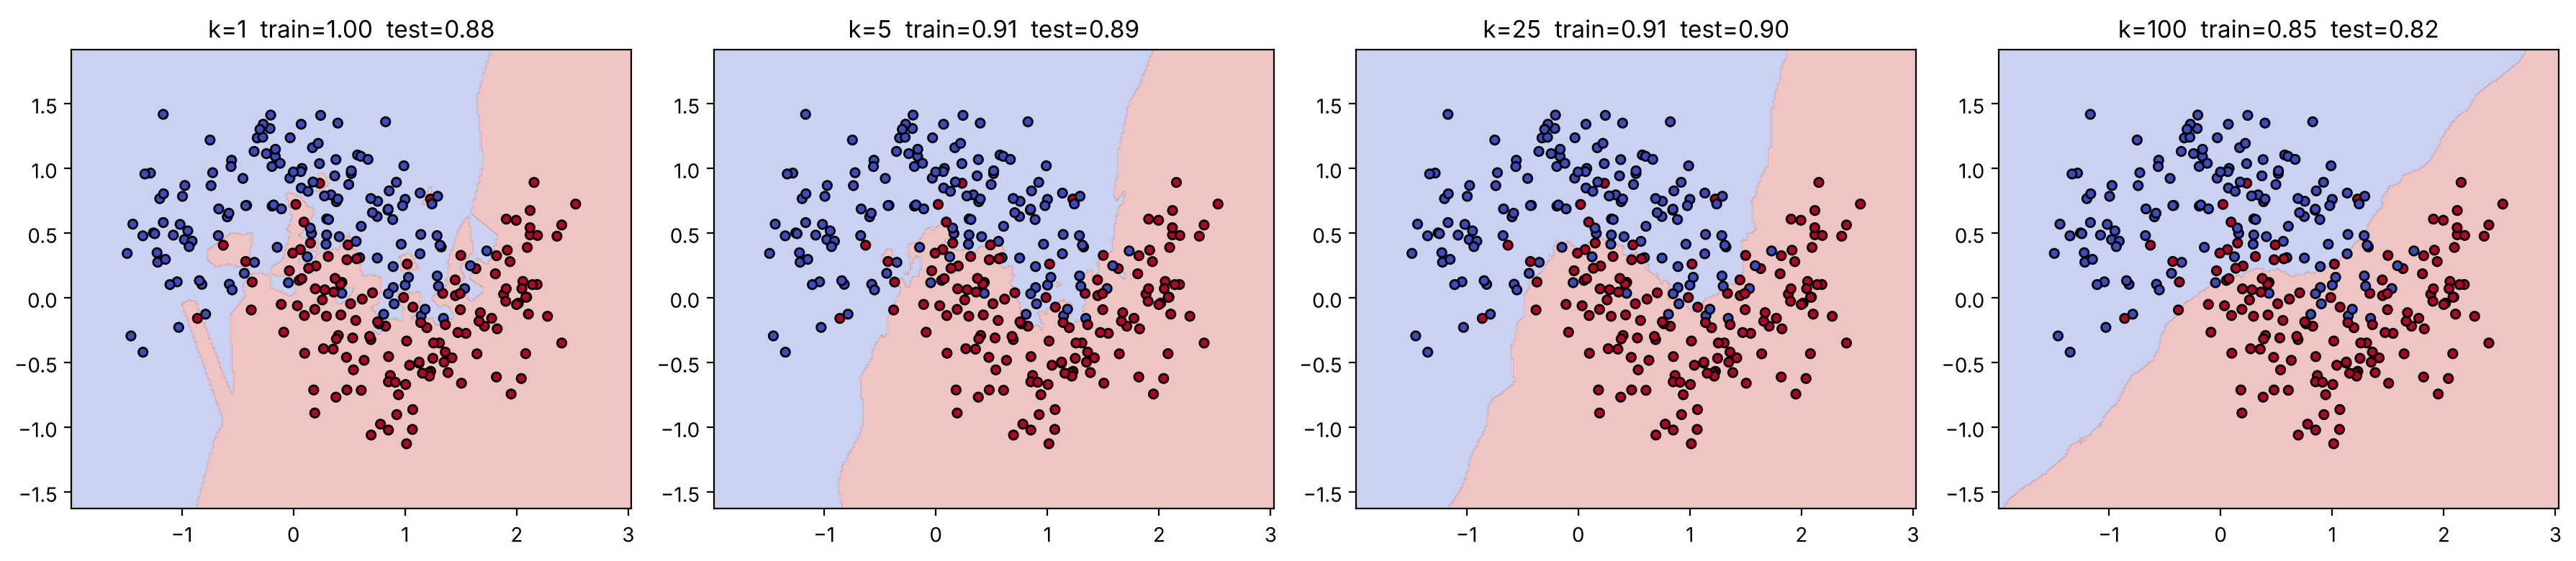

In [3]:
def plot_decision_boundary(model, X, y, ax, title=""):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(title)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, [1, 5, 25, 100]):
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    plot_decision_boundary(model, X_train, y_train, ax,
                           f"k={k}  train={model.score(X_train, y_train):.2f}  test={model.score(X_test, y_test):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

- $k=1$: مرز بسیار ناهموار است و هر نقطه‌ی نویزی جزیره‌ی خودش را دارد. **بیش‌برازش**: دقت آموزش ۱۰۰٪.
- $k$ متوسط: مرز نرم و منطقی است.
- $k$ خیلی بزرگ: مرز بیش از حد ساده می‌شود. **کم‌برازش**.

پس $k$ کوچک یعنی واریانس زیاد و $k$ بزرگ یعنی بایاس زیاد؛ همان مصالحه‌ی جلسه‌ی ۴. برای مسائل دوکلاسه، $k$ را معمولاً فرد انتخاب می‌کنند تا رأی مساوی پیش نیاید.

## ۴. انتخاب $k$ با اعتبارسنجی متقابل

</div>

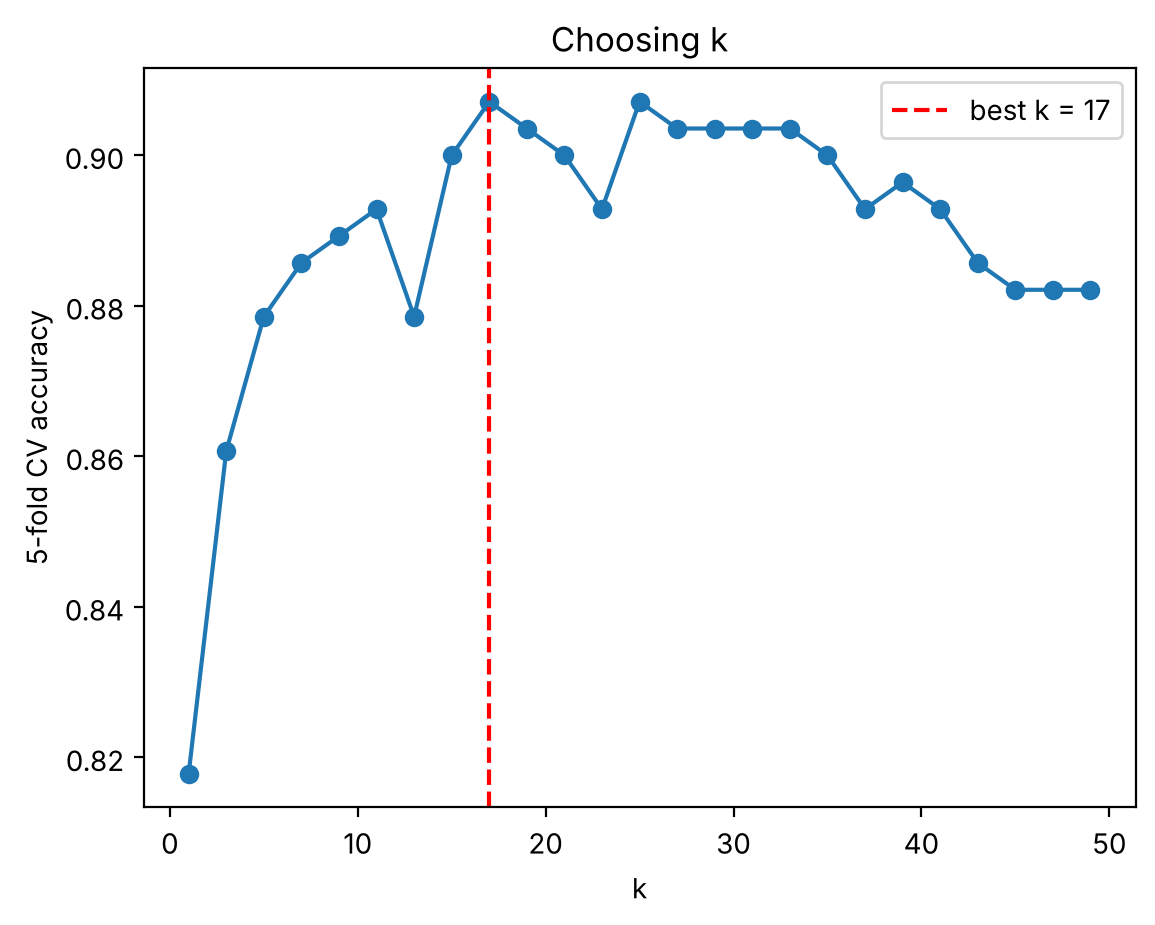

In [4]:
from sklearn.model_selection import cross_val_score

ks = range(1, 51, 2)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in ks]
best_k = list(ks)[int(np.argmax(cv_scores))]

plt.plot(ks, cv_scores, "o-")
plt.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k")
plt.ylabel("5-fold CV accuracy")
plt.title("Choosing k")
plt.legend()
plt.show()

<div dir="rtl">

## ۵. چرا مقیاس‌بندی برای k-NN حیاتی است؟

k-NN کاملاً بر **فاصله** تکیه دارد. اگر یک ویژگی بین ۰ تا ۱۰۰۰ و دیگری بین ۰ تا ۱ باشد، فاصله عملاً فقط به ویژگی اول بستگی پیدا می‌کند. در داده‌ی **Wine**، ویژگی `proline` تا حدود ۱۷۰۰ می‌رسد، در حالی که ویژگی‌هایی مثل `hue` حدود ۱ هستند.

</div>

In [5]:
from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

wine = load_wine(as_frame=True)
print(wine.data[["proline", "magnesium", "alcohol", "hue"]].describe().loc[["min", "max"]].round(2))

without = cross_val_score(KNeighborsClassifier(), wine.data, wine.target, cv=5).mean()
with_scaling = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                               wine.data, wine.target, cv=5).mean()
print(f"\nk-NN without scaling: {without:.3f}")
print(f"k-NN with scaling:    {with_scaling:.3f}")

     proline  magnesium  alcohol   hue
min    278.0       70.0    11.03  0.48
max   1680.0      162.0    14.83  1.71

k-NN without scaling: 0.691
k-NN with scaling:    0.949


<div dir="rtl">

فقط با اضافه کردن یک `StandardScaler`، دقت به‌طور چشمگیری بالا می‌رود. **هرگز k-NN را بدون مقیاس‌بندی اجرا نکنید.**

## ۶. نفرین ابعاد (Curse of Dimensionality)

با افزایش تعداد ویژگی‌ها، فضا آن‌قدر بزرگ و خالی می‌شود که «نزدیک‌ترین» همسایه هم دیگر نزدیک نیست. در ابعاد بالا، فاصله‌ی نزدیک‌ترین و دورترین نقطه تقریباً یکسان می‌شود و مفهوم «همسایگی» معنایش را از دست می‌دهد:

</div>

In [6]:
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000]:
    points = rng.random((1000, d))
    dist = np.sqrt(((points[1:] - points[0]) ** 2).sum(axis=1))
    print(f"dimensions={d:>4}  nearest/farthest distance ratio = {dist.min() / dist.max():.3f}")

dimensions=   2  nearest/farthest distance ratio = 0.006
dimensions=  10  nearest/farthest distance ratio = 0.287
dimensions= 100  nearest/farthest distance ratio = 0.699
dimensions=1000  nearest/farthest distance ratio = 0.900


<div dir="rtl">

وقتی این نسبت به ۱ نزدیک می‌شود، همه‌ی نقاط تقریباً به یک اندازه دورند. به همین دلیل k-NN در داده‌های با ابعاد بسیار بالا ضعیف عمل می‌کند و معمولاً قبل از آن **کاهش ابعاد** (جلسه‌ی ۱۲) یا انتخاب ویژگی انجام می‌شود.

**مزایا و معایب k-NN**

| مزایا | معایب |
|---|---|
| بسیار ساده و قابل فهم | پیش‌بینی کند برای داده‌ی بزرگ |
| بدون فرض درباره‌ی شکل داده | حساس به مقیاس و ویژگی‌های بی‌ربط |
| به‌راحتی چندکلاسه می‌شود | ضعیف در ابعاد بالا |

</div>

<div dir="rtl">

## بخش دوم: Naive Bayes

## ۷. قضیه‌ی بیز

Naive Bayes بر پایه‌ی **قضیه‌ی بیز** است. می‌خواهیم احتمال کلاس $y$ را با دانستن ویژگی‌های $\mathbf{x}$ حساب کنیم:

</div>

$$P(y \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid y)\, P(y)}{P(\mathbf{x})}$$

<div dir="rtl">

- $P(y)$: **احتمال پیشین (prior)**؛ مثلاً چند درصد ایمیل‌ها هرزنامه‌اند.
- $P(\mathbf{x} \mid y)$: **درست‌نمایی (likelihood)**؛ احتمال دیدن این ویژگی‌ها در کلاس $y$.
- $P(y \mid \mathbf{x})$: **احتمال پسین (posterior)**؛ چیزی که می‌خواهیم.

### فرض «ساده‌لوحانه»

تخمین $P(\mathbf{x} \mid y)$ برای همه‌ی ترکیب‌های ممکن ویژگی‌ها غیرممکن است. Naive Bayes فرض می‌کند ویژگی‌ها **با دانستن کلاس، مستقل از هم‌اند**:

</div>

$$P(y \mid \mathbf{x}) \propto P(y) \prod_{j=1}^{n} P(x_j \mid y)$$

<div dir="rtl">

این فرض تقریباً هیچ‌وقت درست نیست (در یک متن، کلمه‌های «خیلی» و «خوب» مستقل نیستند)، ولی Naive Bayes در عمل، مخصوصاً برای **متن**، شگفت‌انگیز خوب کار می‌کند. همچنین بسیار سریع است و با داده‌ی کم هم خوب یاد می‌گیرد.

### انواع Naive Bayes

| نوع | فرض برای $P(x_j \mid y)$ | مناسب برای |
|---|---|---|
| `GaussianNB` | توزیع نرمال | ویژگی‌های عددی پیوسته |
| `MultinomialNB` | توزیع چندجمله‌ای (شمارش) | تعداد تکرار کلمات در متن |
| `BernoulliNB` | توزیع برنولی (صفر و یک) | وجود یا عدم وجود کلمه |

</div>

In [7]:
from sklearn.naive_bayes import GaussianNB

gnb_score = cross_val_score(GaussianNB(), wine.data, wine.target, cv=5).mean()
print(f"Gaussian Naive Bayes on Wine (5-fold CV): {gnb_score:.3f}")

Gaussian Naive Bayes on Wine (5-fold CV): 0.966


<div dir="rtl">

## ۸. طبقه‌بندی متن: نظرهای مشتریان رستوران

مجموعه‌داده‌ی ما ۱۰۰۰ نظر انگلیسی کوتاه درباره‌ی یک رستوران است که هر کدام برچسب «پسندیده» (۱) یا «نپسندیده» (۰) دارد. این یک مسئله‌ی **تحلیل احساسات (Sentiment Analysis)** است.

</div>

In [8]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
reviews = pd.read_csv(DATA_URL + "Restaurant_Reviews.tsv", sep="\t", quoting=3)
print(reviews.shape)
print(reviews["Liked"].value_counts())
reviews.sample(5, random_state=1)

(1000, 2)
Liked
1    500
0    500
Name: count, dtype: int64


,Review,Liked
507,My gyro was basically lettuce only.,0
818,It kept getting worse and worse so now I'm off...,0
452,I am far from a sushi connoisseur but I can de...,0
368,"The staff are great, the ambiance is great.",1
242,By this time our side of the restaurant was al...,0


<div dir="rtl">

### ۸.۱ تبدیل متن به عدد: مدل کیسه‌ی کلمات (Bag of Words)

مدل‌ها با عدد کار می‌کنند، پس هر متن را به برداری از **تعداد تکرار کلمات** تبدیل می‌کنیم. ترتیب کلمات نادیده گرفته می‌شود؛ مثل اینکه کلمات را در یک کیسه بریزیم.

</div>

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

examples = ["The food was good", "The food was not good", "Great service, great food"]
vectorizer = CountVectorizer()
counts = vectorizer.fit_transform(examples)
pd.DataFrame(counts.toarray(), columns=vectorizer.get_feature_names_out(), index=examples)

,food,good,great,not,service,the,was
The food was good,1,1,0,0,0,1,1
The food was not good,1,1,0,1,0,1,1
"Great service, great food",1,0,2,0,1,0,0


<div dir="rtl">

به محدودیت مهم توجه کنید: «good» و «not good» تقریباً بردار یکسانی دارند. با در نظر گرفتن **جفت کلمات متوالی (bigram)** با `ngram_range=(1, 2)`، عبارت «not good» هم یک ویژگی مستقل می‌شود.

**TF-IDF** نسخه‌ی بهتری از شمارش ساده است: کلماتی که در همه‌ی متن‌ها تکرار می‌شوند (مثل «the») وزن کمتری می‌گیرند و کلمات خاص و متمایزکننده وزن بیشتر.

</div>

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \log\frac{1 + N}{1 + \text{df}(t)} + 1$$

<div dir="rtl">

که $N$ تعداد کل اسناد و $\text{df}(t)$ تعداد اسنادی است که کلمه‌ی $t$ را دارند.

### ۸.۲ ساختن و ارزیابی مدل

</div>

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X_text, y_text = reviews["Review"], reviews["Liked"]
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_text, y_text, test_size=0.2, stratify=y_text, random_state=42)

text_models = {
    "Count + MultinomialNB": make_pipeline(CountVectorizer(), MultinomialNB()),
    "TF-IDF (1-2 grams) + MultinomialNB": make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB()),
    "TF-IDF (1-2 grams) + LogisticRegression": make_pipeline(TfidfVectorizer(ngram_range=(1, 2)),
                                                             LogisticRegression(max_iter=1000)),
}
for name, model in text_models.items():
    cv = cross_val_score(model, Xt_train, yt_train, cv=5).mean()
    print(f"{name:<42} CV accuracy = {cv:.3f}")

Count + MultinomialNB                      CV accuracy = 0.815
TF-IDF (1-2 grams) + MultinomialNB         CV accuracy = 0.799


TF-IDF (1-2 grams) + LogisticRegression    CV accuracy = 0.785


<div dir="rtl">

با فقط ۸۰۰ جمله‌ی کوتاه آموزشی، Naive Bayes حدود ۸۰٪ دقت دارد. جالب اینکه اینجا ساده‌ترین ترکیب (شمارش کلمات و Naive Bayes) از بقیه بهتر است؛ با داده‌ی کم، مدل‌های ساده‌تر معمولاً بیش‌برازش کمتری دارند. اختلاف‌ها کوچک است، ولی طبق روش درست، مدلی را انتخاب می‌کنیم که در **اعتبارسنجی متقابل** بهترین بوده و فقط همان را روی داده‌ی آزمون ارزیابی می‌کنیم:

</div>

In [11]:
nb_model = text_models["Count + MultinomialNB"].fit(Xt_train, yt_train)
print(classification_report(yt_test, nb_model.predict(Xt_test), target_names=["disliked", "liked"], digits=3))

              precision    recall  f1-score   support

    disliked      0.818     0.810     0.814       100
       liked      0.812     0.820     0.816       100

    accuracy                          0.815       200
   macro avg      0.815     0.815     0.815       200
weighted avg      0.815     0.815     0.815       200



<div dir="rtl">

### ۸.۳ مدل چه چیزی یاد گرفته است؟

یکی از مزیت‌های Naive Bayes تفسیرپذیری آن است. برای هر کلمه، نسبت احتمال آن در نظرهای مثبت به منفی را حساب می‌کنیم:

</div>

In [12]:
vec = nb_model.named_steps["countvectorizer"]
nb = nb_model.named_steps["multinomialnb"]
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
words = vec.get_feature_names_out()

top = pd.DataFrame({
    "most positive": words[np.argsort(log_ratio)[-12:][::-1]],
    "most negative": words[np.argsort(log_ratio)[:12]],
})
top

,most positive,most negative
0,great,minutes
1,delicious,bad
2,awesome,wasn
3,excellent,being
4,loved,bland
5,happy,slow
6,fantastic,terrible
7,perfect,probably
8,atmosphere,no
9,cooked,getting


In [13]:
new_reviews = [
    "The pasta was absolutely delicious and the staff were friendly",
    "Terrible service, cold food and we waited an hour",
    "Not bad, but not great either",
]
for text, p in zip(new_reviews, nb_model.predict_proba(new_reviews)[:, 1]):
    print(f"P(liked) = {p:.2f}  |  {text}")

P(liked) = 1.00  |  The pasta was absolutely delicious and the staff were friendly
P(liked) = 0.00  |  Terrible service, cold food and we waited an hour
P(liked) = 0.02  |  Not bad, but not great either


<div dir="rtl">

جمله‌ی سوم نشان می‌دهد مدل‌های کیسه‌ی کلمات در فهم نفی و ظرافت‌های زبانی محدودیت دارند. برای این موارد به مدل‌های زبانی پیشرفته‌تر (مثل ترنسفورمرها) نیاز است که خارج از محدوده‌ی این دوره‌اند.

### ۸.۴ هموارسازی لاپلاس

اگر کلمه‌ای در داده‌ی آموزش هرگز در نظرهای مثبت نیامده باشد، $P(\text{word} \mid \text{liked}) = 0$ می‌شود و به خاطر ضرب احتمال‌ها، کل احتمال صفر می‌شود؛ فقط به خاطر یک کلمه! **هموارسازی لاپلاس** با اضافه کردن یک مقدار کوچک $\alpha$ به همه‌ی شمارش‌ها این مشکل را حل می‌کند. پارامتر `alpha` در `MultinomialNB` همین است (پیش‌فرض ۱) و می‌توان آن را با اعتبارسنجی تنظیم کرد.

## ۹. جمع‌بندی

- k-NN بر اساس رأی $k$ همسایه‌ی نزدیک پیش‌بینی می‌کند؛ $k$ کوچک بیش‌برازش و $k$ بزرگ کم‌برازش می‌دهد.
- مقیاس‌بندی برای k-NN حیاتی است و این الگوریتم در ابعاد بالا ضعیف می‌شود.
- Naive Bayes با قضیه‌ی بیز و فرض استقلال ویژگی‌ها، طبقه‌بندی سریع و ساده‌ای ارائه می‌دهد.
- برای متن: متن را با Bag of Words یا TF-IDF به بردار تبدیل کنید؛ MultinomialNB یک مدل پایه‌ی قوی است.

## ۱۰. تمرین

1. k-NN را با `weights="distance"` امتحان کنید (همسایه‌های نزدیک‌تر رأی سنگین‌تری دارند). روی داده‌ی moons چه تغییری می‌بینید؟
2. `KNeighborsRegressor` را روی داده‌ی مسکن جلسه‌ی ۳ اجرا کنید (با مقیاس‌بندی) و RMSE آن را با رگرسیون خطی مقایسه کنید.
3. در مدل متنی، `stop_words="english"` را به `TfidfVectorizer` اضافه کنید. دقت تغییر می‌کند؟ چرا حذف کلماتی مثل «not» می‌تواند مضر باشد؟
4. `alpha` در `MultinomialNB` را با مقادیر ۰٫۰۱، ۰٫۱، ۰٫۵ و ۱ امتحان کنید و بهترین مقدار را با اعتبارسنجی متقابل پیدا کنید.

</div>